In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import jax
import seaborn as sns

jax.config.update('jax_platforms', 'cpu')

plt.rcParams['font.family'] = 'Helvetica Light'

from behavioral_plotting import (
    load_odor_site_df,
    plot_stop_fraction,
)
from aux_funcs import format_plot, zero_pad
from nb_analysis_tools import *

from pathlib import Path
FIGURES_DIR = Path('../../../figures/motifs_analysis')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [18]:
# Trajectory files sampled across training of structure_evo_exp_gru_initial_prob_offset_reward_normed
# (same network as motifs_analysis_figures.ipynb; steps 0–1975 in increments of 25)
_TRAJ_ROOT = '../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00'

CHECKPOINT_STEPS = np.arange(50, 2000, 50)

TRAJ_PATHS = [
    f'{_TRAJ_ROOT}/traj_{step:06d}.pkl'
    for step in CHECKPOINT_STEPS
]

for p in TRAJ_PATHS:
    from pathlib import Path
    print(p, '  exists:', Path(p).exists())

../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000050.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000100.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000150.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000200.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000250.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000300.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000350.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000400.pkl   exists: True
../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_000450.pkl   exist

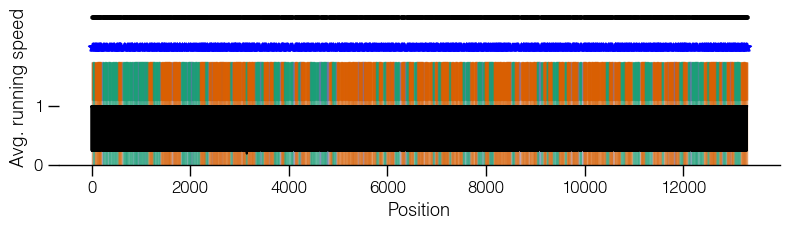

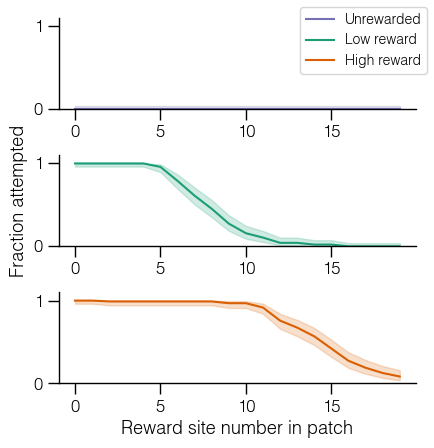

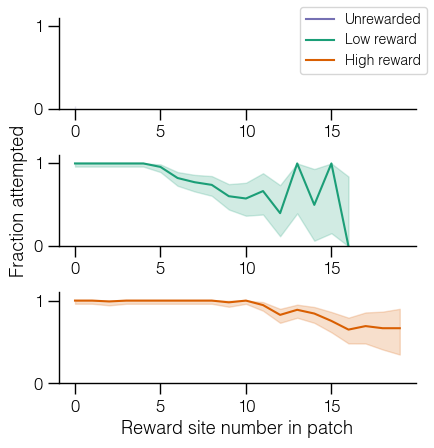

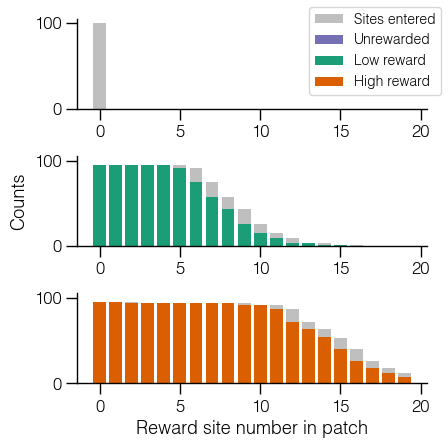

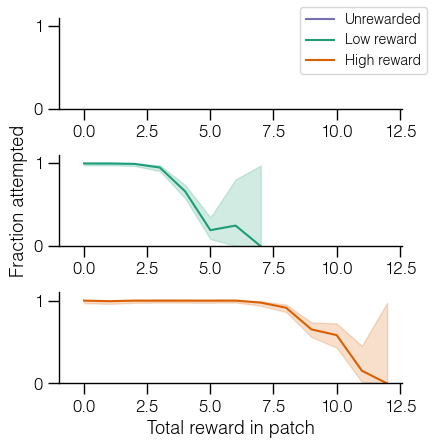

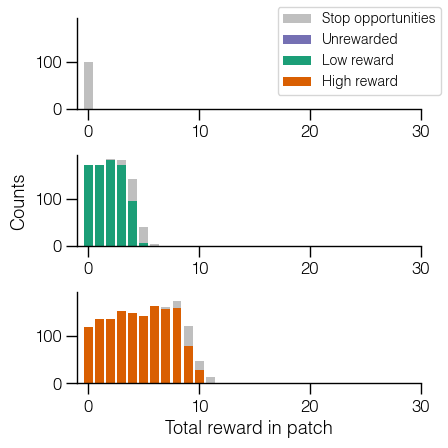

In [58]:
from behavioral_plotting import plot_session

_TRAJ_1900 = '../../../results/structure_evo_exp_gru_initial_prob_offset_reward_normed/step_00/traj_001900.pkl'
plot_session(_TRAJ_1900, session_idx=0, max_reward_sites=20)
plt.show()


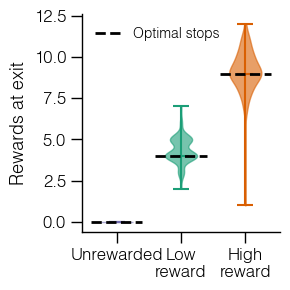

In [82]:
from behavioral_plotting import plot_fraction_attempted_violin

plot_fraction_attempted_violin(_TRAJ_1900, optimal_stops=[0, 4, 9],
                               save_dir=str(FIGURES_DIR),
                               save_name='fraction_leaving_violin')
plt.show()

In [19]:
dfs = [
    load_odor_site_df(path, nn_num=nn_num)
    for nn_num, path in enumerate(TRAJ_PATHS)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries ge

## Accumulated reward against consecutive failures

In [44]:
# for step, df in zip(CHECKPOINT_STEPS, dfs):
#     print(f'\n=== checkpoint {step} ===')
#     for patch_type in [0, 1, 2]:
#         plot_stop_fraction(
#             df,
#             'consecutive_misses',
#             'rewards_seen_in_patch',
#             invert_y=True,
#             condition=lambda x, pt=patch_type: x[x['patch_type'] == pt],
#             figsize=(5, 5),
#             reverse=True,
#             xlabel='Consecutive Failures',
#             ylabel='Cumulative Rewards',
#             min_n=10,
#             vmax=0.5,
#         )
#         plt.suptitle(f'checkpoint {step}  |  patch type {patch_type}', fontsize=9)
#         plt.tight_layout()
#         plt.show()
# None

## P(stop) / P(leave) / P(reward), per checkpoint

Two panels per checkpoint, reproducing the reference h/i structure. **Left:** P(stop) at the first
odor site of a patch (`rewards_seen_in_patch==0 & consecutive_misses==0`) for patch types
2/1/0 = High/Low/Null. **Right:** P(leave) = 1 - P(stop) after one failure (`consecutive_misses==1`) for High/Low
(Null omitted \u2014 the agent essentially never stops there). One session per checkpoint, so error
bars are binomial SEs over the patch-level stop decisions.

**Third panel:** P(reward) at the site where the agent leaves (last odor site of each patch), for High/Low,
`prefactor * exp(-rewards_seen / decay_const)`, mean +/- SE across patches, per patch type.

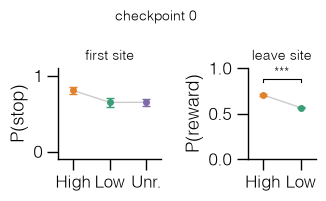

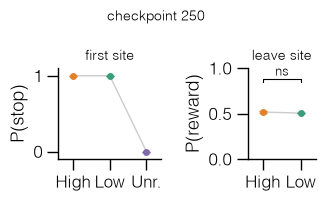

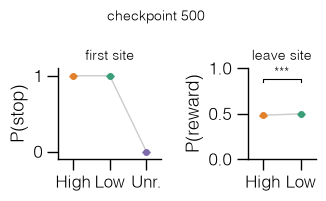

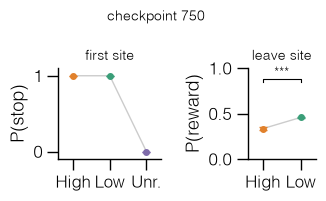

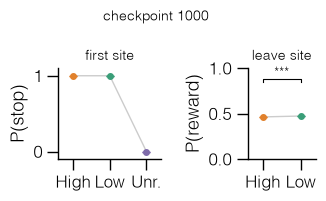

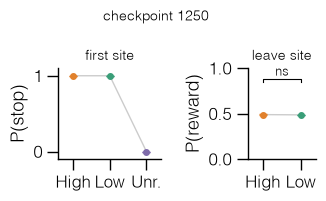

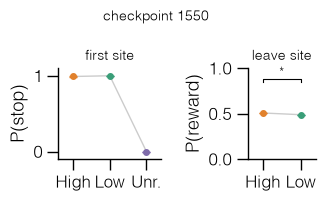

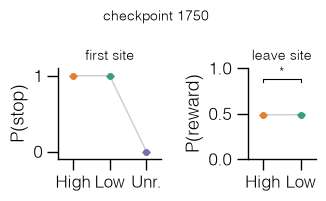

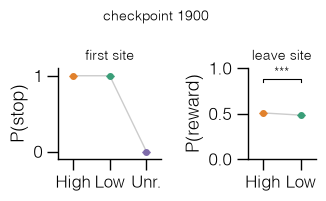

In [9]:
from scipy import stats

PTYPE_LABEL = {2: 'High', 1: 'Low', 0: 'Unr.'}
PTYPE_COLOR = {2: '#E1812C', 1: '#3A9E78', 0: '#7E6BAA'}   # orange / green / purple

def _pstop(sub, t):
    s = sub.loc[sub['patch_type'] == t, 'stopped'].to_numpy()
    if s.size == 0:
        return np.nan, 0.0
    p = float(s.mean())
    return p, float(np.sqrt(p * (1 - p) / s.size))

def _pr_leave(df, t):
    """Mean +/- SE of the reward probability at the site where the agent LEAVES (last odor site of
    each patch): prefactor * exp(-rewards_seen / decay_const)."""
    last = df[df['patch_type'] == t].groupby(['session_number', 'patch_number']).tail(1)
    pr = (last['patch_reward_prob_prefactor'].to_numpy()
          * np.exp(-last['rewards_seen_in_patch'].to_numpy()
                   / (last['patch_reward_param'].to_numpy() + 1e-9)))
    if pr.size == 0:
        return np.nan, 0.0
    return float(pr.mean()), (float(pr.std(ddof=1) / np.sqrt(pr.size)) if pr.size > 1 else 0.0)

def _pr_leave_raw(df, t):
    """Per-patch P(reward) at the leave site (raw array for statistical testing)."""
    last = df[df['patch_type'] == t].groupby(['session_number', 'patch_number']).tail(1)
    return (last['patch_reward_prob_prefactor'].to_numpy()
            * np.exp(-last['rewards_seen_in_patch'].to_numpy()
                     / (last['patch_reward_param'].to_numpy() + 1e-9)))

def _draw_panel(ax, types, yse, ylabel, title, ylim=None):
    xs = np.arange(len(types))
    ax.plot(xs, [y for y, _ in yse], color='0.8', lw=1, zorder=1)               # faint trend guide
    for x, t, (y, se) in zip(xs, types, yse):
        ax.errorbar(x, y, yerr=se, fmt='o', ms=4, color=PTYPE_COLOR[t],
                    ecolor=PTYPE_COLOR[t], capsize=3, zorder=2)
    ax.set_xticks(xs)
    ax.set_xticklabels([PTYPE_LABEL[t] for t in types])
    ax.set_xlim(-0.4, len(types) - 0.6)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=10)
    format_plot(ax)

def plot_pstop_first_and_after_failure(df, title='', figsize=(7.8, 3.0), save_dir=None, save_stem='plot'):
    first  = df[(df['rewards_seen_in_patch'] == 0) & (df['consecutive_misses'] == 0)]  # first odor site
    fig, (axL, axR) = plt.subplots(1, 2, figsize=figsize,
                                   gridspec_kw={'width_ratios': [3, 2]})
    # P(stop) at first site (High/Low/Null)
    _draw_panel(axL, [2, 1, 0], [_pstop(first, t) for t in (2, 1, 0)], 'P(stop)', 'first site', ylim=(-0.1, 1.1))
    # P(reward) at the site where the agent leaves (High/Low)
    _draw_panel(axR, [2, 1], [_pr_leave(df, t) for t in (2, 1)], 'P(reward)', 'leave site', ylim=(0, 1))
    # Mann-Whitney U: P(reward) at leave, High vs Low
    _hi = _pr_leave_raw(df, 2)
    _lo = _pr_leave_raw(df, 1)
    if _hi.size > 0 and _lo.size > 0:
        _, _p = stats.mannwhitneyu(_hi, _lo, alternative='two-sided')
        _stars = ('***' if _p < 0.001 else '**' if _p < 0.01
                  else '*' if _p < 0.05 else 'ns')
        _ylo, _yhi = axR.get_ylim()
        _bar_y  = _ylo + (_yhi - _ylo) * 0.88
        _tick_h = (_yhi - _ylo) * 0.03
        axR.set_ylim(_ylo, _yhi)   # hold limits before drawing
        axR.plot([0, 0, 1, 1],
                 [_bar_y - _tick_h, _bar_y, _bar_y, _bar_y - _tick_h],
                 lw=0.8, color='k', clip_on=False)
        axR.text(0.5, _bar_y + (_yhi - _ylo) * 0.01, _stars,
                 ha='center', va='bottom', fontsize=9, color='k')
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        for _ext, _dpi in (('pdf', None), ('png', 150), ('svg', None)):
            fig.savefig(os.path.join(save_dir, f'{save_stem}.{_ext}'),
                        bbox_inches='tight', **(dict(dpi=_dpi) if _dpi else {}))
    plt.show()

_pstop_dir = FIGURES_DIR / 'pstop_leave'
_pstop_dir.mkdir(parents=True, exist_ok=True)
for step, df in zip(CHECKPOINT_STEPS, dfs):
    plot_pstop_first_and_after_failure(df, title=f'checkpoint {step}', figsize=(3.5, 2),
                                       save_dir=str(_pstop_dir), save_stem=f'checkpoint_{step:06d}')


## Reaction time vs site number (relative to leave), per checkpoint

For each patch, number its odor sites **relative to the leave site** (`rel = index - max index in
patch`; 0 = the leave site, negative = sites before it). `reaction_time` is the RT (timesteps) at
each STOPPED site \u2014 it's NaN at the leave site itself (the agent doesn't stop), so points appear at
rel < 0. Mean +/- SE across patches per relative site, for High/Low. RT typically spikes at the last
stop before leaving (rel = -1).

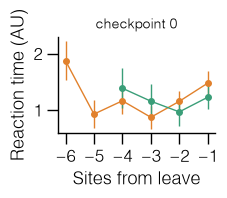

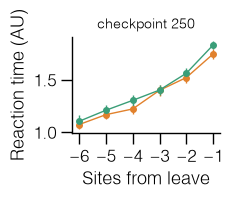

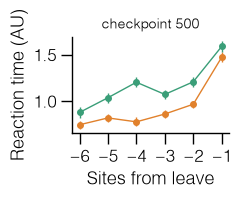

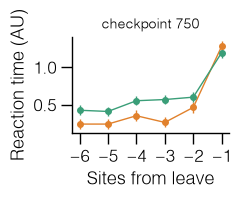

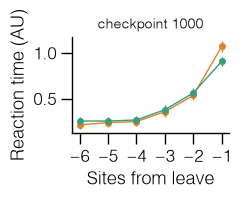

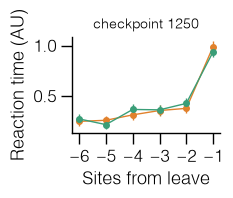

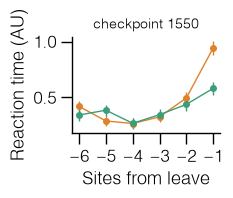

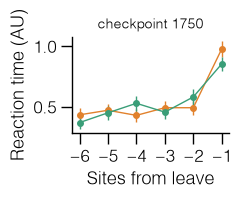

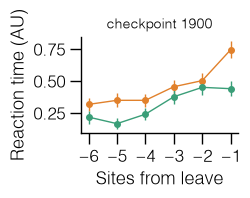

In [10]:
def plot_rt_relative_to_leave(df, patch_types=(2, 1), min_rel=-6, min_n=15, title='', figsize=(4.6, 3.0), save_dir=None, save_stem='plot', combine_rewarded=False):
    fig, ax = plt.subplots(figsize=figsize)
    if combine_rewarded:
        parts = []
        for t in patch_types:
            sub = df[df['patch_type'] == t].copy()
            last = sub.groupby(['session_number', 'patch_number'])['index'].transform('max')
            sub['rel'] = sub['index'] - last
            parts.append(sub)
        combined = pd.concat(parts)
        combined = combined[(combined['rel'] >= min_rel) & combined['reaction_time'].notna()]
        grp = combined.groupby('rel')['reaction_time']
        m, sd, n = grp.mean(), grp.std(), grp.count()
        keep = (n >= min_n).to_numpy()
        x = m.index.to_numpy()[keep]
        ax.errorbar(x, m.to_numpy()[keep], yerr=(sd / np.sqrt(n)).to_numpy()[keep],
                    fmt='o-', ms=4, lw=1, color='k', ecolor='k', capsize=0)
    else:
        for t in patch_types:
            sub = df[df['patch_type'] == t].copy()
            last = sub.groupby(['session_number', 'patch_number'])['index'].transform('max')
            sub['rel'] = sub['index'] - last                          # 0 = leave site, -1 = last stop, ...
            sub = sub[(sub['rel'] >= min_rel) & sub['reaction_time'].notna()]
            grp = sub.groupby('rel')['reaction_time']
            m, sd, n = grp.mean(), grp.std(), grp.count()
            keep = (n >= min_n).to_numpy()
            x = m.index.to_numpy()[keep]
            ax.errorbar(x, m.to_numpy()[keep], yerr=(sd / np.sqrt(n)).to_numpy()[keep],
                        fmt='o-', ms=4, lw=1, color=PTYPE_COLOR[t], ecolor=PTYPE_COLOR[t],
                        capsize=0, label=PTYPE_LABEL[t])
    ax.set_xlabel('Sites from leave')
    ax.set_ylabel('Reaction time (AU)')
    ax.set_title(title, fontsize=10)
    ax.set_xticks([-6, -5, -4, -3, -2, -1])
    # ax.legend(fontsize=8, frameon=False, title='Patch type')
    format_plot(ax)
    fig.tight_layout()
    if save_dir is not None:
        os.makedirs(save_dir, exist_ok=True)
        for _ext, _dpi in (('pdf', None), ('png', 150), ('svg', None)):
            fig.savefig(os.path.join(save_dir, f'{save_stem}.{_ext}'),
                        bbox_inches='tight', **(dict(dpi=_dpi) if _dpi else {}))
    plt.show()

_rt_dir = FIGURES_DIR / 'rt_relative_leave'
_rt_dir.mkdir(parents=True, exist_ok=True)
for step, df in zip(CHECKPOINT_STEPS, dfs):
    plot_rt_relative_to_leave(df, title=f'checkpoint {step}', figsize=(2.5, 2.0),
                              save_dir=str(_rt_dir), save_stem=f'checkpoint_{step:06d}')

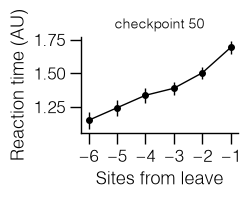

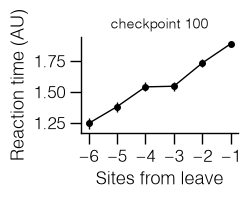

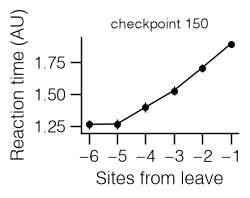

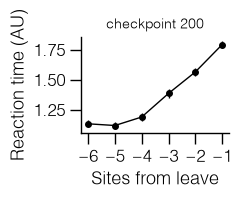

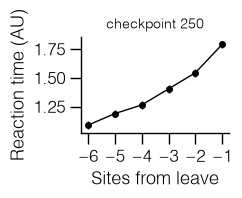

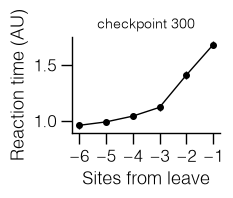

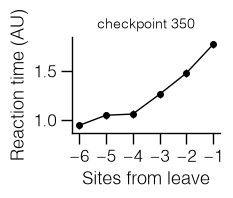

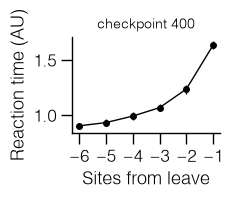

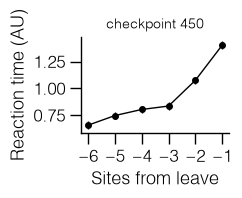

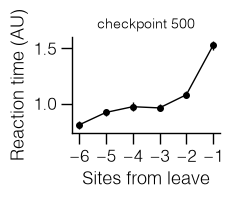

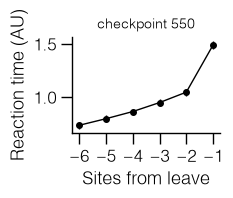

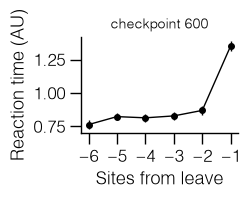

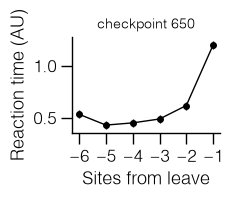

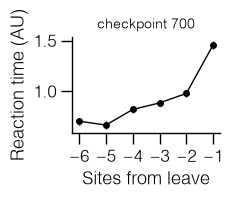

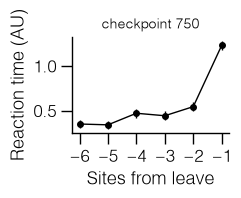

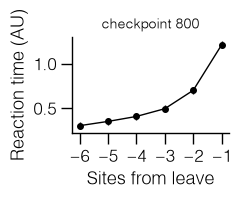

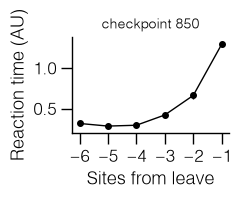

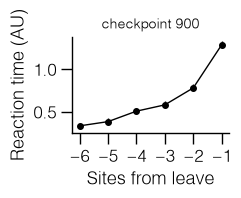

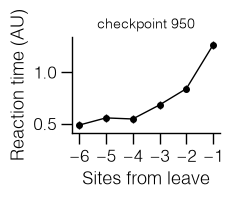

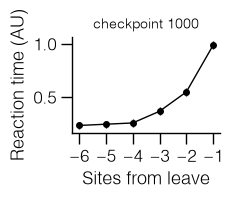

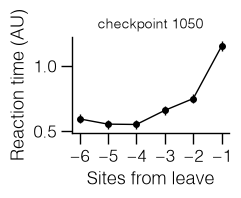

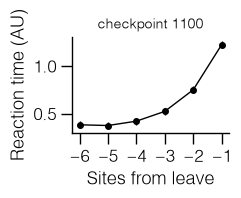

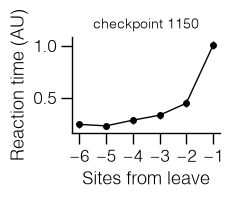

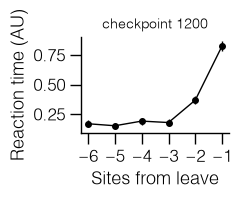

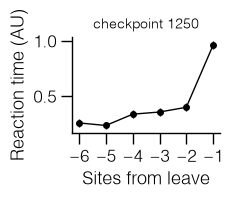

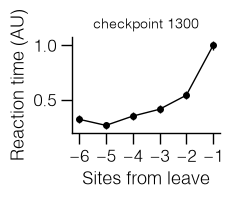

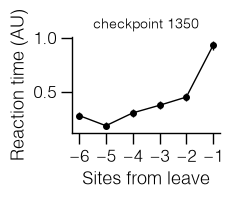

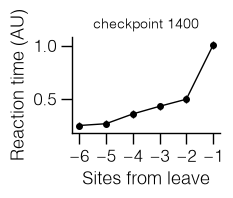

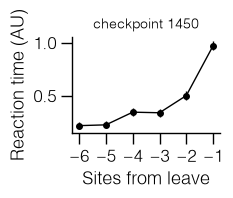

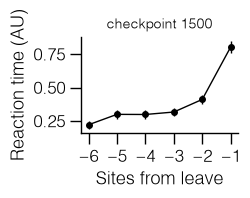

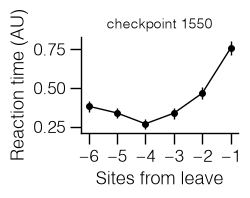

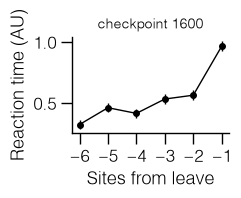

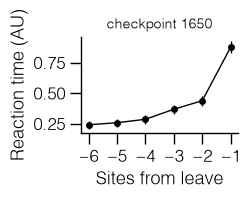

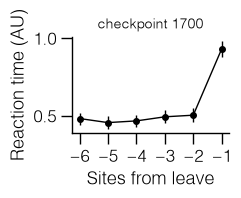

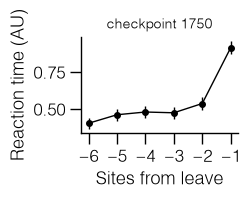

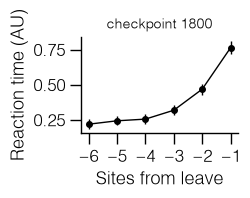

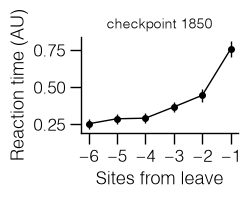

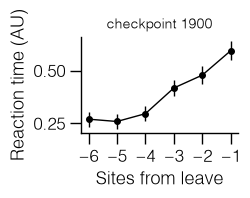

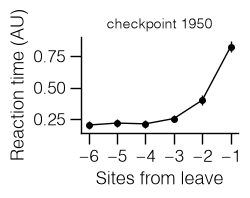

50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950
1000
1050
1100
1150
1200
1250
1300
1350
1400
1450
1500
1550
1600
1650
1700
1750
1800
1850
1900
1950


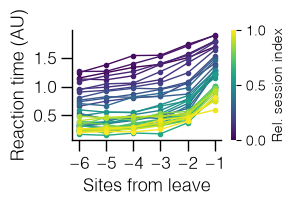

In [23]:
_rt_combined_dir = FIGURES_DIR / 'rt_relative_leave_combined'
_rt_combined_dir.mkdir(parents=True, exist_ok=True)
for step, df in zip(CHECKPOINT_STEPS, dfs):
    plot_rt_relative_to_leave(df, title=f'checkpoint {step}', figsize=(2.5, 2.0),
                              combine_rewarded=True,
                              save_dir=str(_rt_combined_dir), save_stem=f'checkpoint_{step:06d}')

# All checkpoints on one axis, colored by checkpoint number
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

_min_rel = -6
_min_n = 15
_patch_types = (2, 1)

_cmap = plt.get_cmap('viridis')
_norm = Normalize(vmin=0, vmax=1)

_fig_all, _ax_all = plt.subplots(figsize=(3, 2))

for step, df in zip(CHECKPOINT_STEPS, dfs):
    print(step)
    parts = []
    for t in _patch_types:
        sub = df[df['patch_type'] == t].copy()
        last = sub.groupby(['session_number', 'patch_number'])['index'].transform('max')
        sub['rel'] = sub['index'] - last
        parts.append(sub)
    _combined = pd.concat(parts)
    _combined = _combined[(_combined['rel'] >= _min_rel) & _combined['reaction_time'].notna()]
    _grp = _combined.groupby('rel')['reaction_time']
    _m, _sd, _n = _grp.mean(), _grp.std(), _grp.count()
    _keep = (_n >= _min_n).to_numpy()
    _x = _m.index.to_numpy()[_keep]
    _rel_idx = (step - CHECKPOINT_STEPS[0]) / (CHECKPOINT_STEPS[-1] - CHECKPOINT_STEPS[0])
    _color = _cmap(_norm(_rel_idx))
    _ax_all.plot(_x, _m.to_numpy()[_keep], 'o-', ms=3, lw=1, color=_color)

_ax_all.set_xlabel('Sites from leave')
_ax_all.set_ylabel('Reaction time (AU)')
_ax_all.set_xticks([-6, -5, -4, -3, -2, -1])
format_plot(_ax_all)
_sm = ScalarMappable(cmap=_cmap, norm=_norm)
_sm.set_array([])
_cb = _fig_all.colorbar(_sm, ax=_ax_all, label='Rel. session index')
_cb.outline.set_visible(False)
_fig_all.tight_layout()
_fig_all.savefig(str(_rt_combined_dir / 'all_checkpoints.svg'), format='svg')
plt.show()
